# 실패 로그와 평가 대상

**이 노트북에서 할 일**

1. Ch 12가 남긴 개발 기록 서른여섯 줄과 시험 기록 열다섯 문항을 읽습니다.
2. 두 기록에 답이 적힌 칸이 있는지 셉니다.
3. 정답 문서가 첫 자리에 오지 않은 줄을 모아 실패 로그를 만듭니다.
4. 이 챕터 자료 파일의 평가 사례 세 건을 같은 질문의 검색 기록과 짝짓습니다.
5. 자르는 자리만 5로 바꿔 실패 로그를 다시 만들고 견줍니다.

**준비물** — 이 절은 OpenAI API 키를 쓰지 않습니다.
모델 요청과 임베딩 요청이 모두 0번이라 드는 비용이 없습니다.
이미 남은 기록 파일을 읽어 평가할 사례를 고르는 절이기 때문입니다.

읽는 파일은 Ch 12 실습 폴더의 기록 두 개와 이 챕터 자료 파일 하나입니다.
새로 쓰는 파일은 없습니다.
교재 출력을 만든 실행에서는 노트북 전체가 1초 안에 끝났습니다.

**기준 버전** — 이 절은 Python에 들어 있는 기능과 도구 파일만 씁니다.
따로 설치할 패키지가 없어 설치 셀을 두지 않았습니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~6절을 읽습니다.
Ch 12 기록에서 답 칸을 세고 실패 로그를 만드는 자리입니다.
7~9절은 평가 사례를 읽고 평가 대상 표를 만드는 자리입니다.
10절은 값 바꿔 보기이고 실습 시간에 함께 실행합니다.

실습 폴더 `labs/part4/ch15-evaluation-advanced`에서 `uv sync --locked`를 실행합니다.
그다음 이 폴더의 `.venv` 커널을 고르고 첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도로 맨 위 초록 상자 Ch 12 개발 기록 서른여섯 줄과 초록 상자 Ch 12 시험 기록 열다섯 문항이 파란 상자 정답 자리를 세고 자르는 자리 1로 가르기로 모여 노란 상자 실패 로그 스물일곱 줄 답 칸은 없음으로 이어지고 오른쪽 초록 상자 이 챕터 자료 파일 평가 사례 세 건은 노란 상자 답 칸이 있는 세 건 답 쪽 평가 대상으로 이어지며 두 노란 상자가 맨 아래 노란 상자 Q090은 실패 로그와 평가 사례에 모두 있음으로 모이는 그림](attachment:01-1-실패-로그와-평가-사례.png)

위에서 아래로 읽습니다.
왼쪽 줄기는 Ch 12 기록에서 실패 로그를 만드는 차례입니다.
오른쪽 줄기는 답이 있는 평가 사례를 고르는 차례입니다.
두 줄기가 만나는 맨 아래 상자가 두 쪽에 모두 있는 질문입니다.
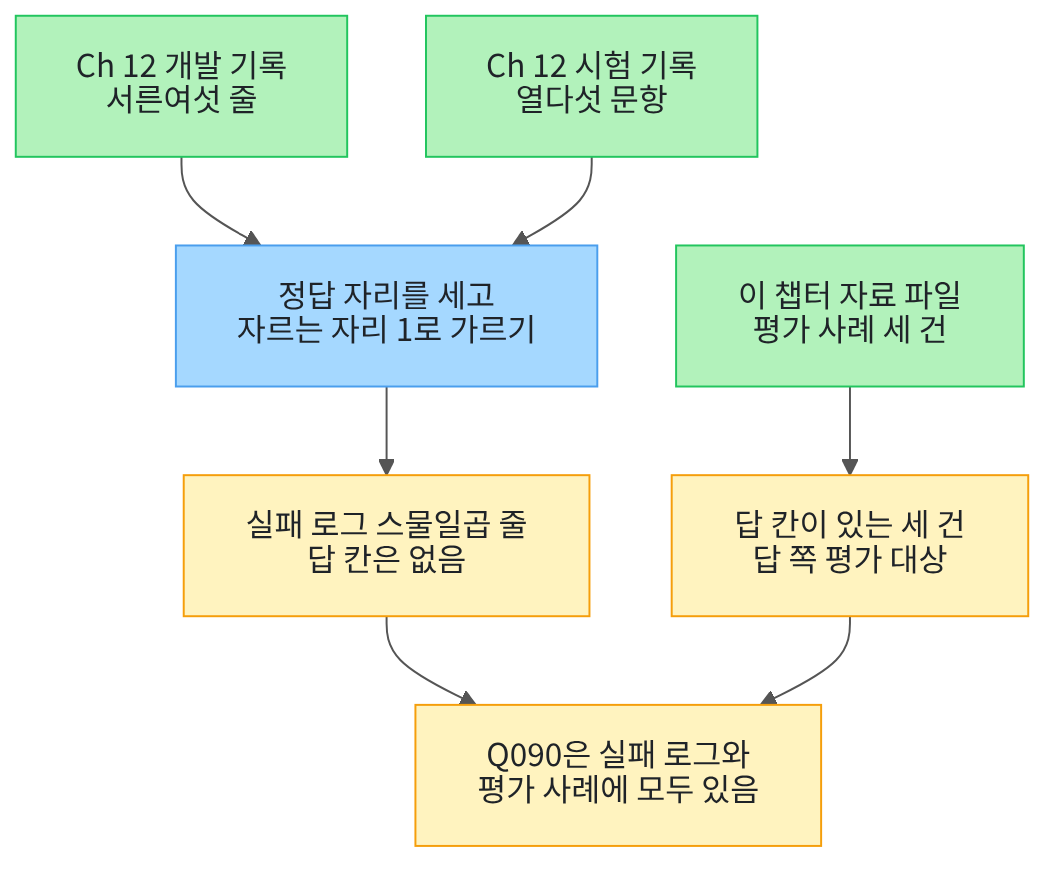

## 1. 준비

이 절은 따로 설치할 패키지가 없습니다.
첫 셀은 이 절에서 쓸 이름을 불러오고 Python 판을 출력합니다.

앞에서 배운 함수는 `rag_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다.
이 노트북은 Ch 11 01절 `unique_doc_ids()`와 `find_gold_rank()`를 가져옵니다.

Ch 11 04절 `rank_weight()`와 05절 `error_name()`도 함께 가져옵니다.
네 함수 모두 Ch 11에서 쓰던 인자 그대로입니다.

In [1]:
# 기록 파일 읽기와 폴더 확인에 쓸 이름을 불러오고 Python 판을 출력합니다
import json
import os
import platform

# Ch 11 01·04·05절에서 배운 함수 넷을 도구 파일에서 가져옵니다
from rag_tools import error_name, find_gold_rank, rank_weight, unique_doc_ids

print("불러온 이름:", "json", "os", "platform")
print("Python 판:", platform.python_version())

불러온 이름: json os platform
Python 판: 3.12.13


**결과 읽기** — 출력 줄 `Python 판: 3.12.13`이 교재 출력을 만든 판입니다.
이름 `json`은 기록 파일을 읽을 때, `os`는 폴더를 찾을 때 씁니다.
도구 파일에서 가져온 함수 네 개는 출력하지 않습니다.
이 노트북의 출력은 2026-09-21에 실행한 결과입니다.

다음 셀은 노트북을 연 자리에서 프로젝트 맨 위를 찾습니다.
Ch 10~14에서 쓴 자리 찾기와 같은 방법입니다.

In [2]:
# 노트북을 어느 폴더에서 열어도 프로젝트 맨 위를 찾게 후보 세 개를 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part4/ch15-evaluation-advanced/data"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위:` 뒤에 점 하나나 위로 올라가는 자리가 보입니다.
후보 셋 가운데 이 챕터 자료 폴더가 있는 자리를 고릅니다.

## 2. Ch 12 개발 기록 읽기

Ch 12 12절은 손잡이 두 개를 곱해 검색 설정 서른여섯 벌을 만들었습니다.
설정 한 벌마다 개발 질문 열다섯 개를 재고 한 줄로 적었습니다.
그 개발 기록 파일을 읽어 줄 수부터 셉니다.

In [3]:
# Ch 12 12절이 남긴 개발 기록을 한 줄씩 읽어 목록에 담습니다(읽기만 합니다)
ch12_runs = root_path + "/labs/part3/ch12-retrieval-tuning/runs"
dev_rows = []
with open(ch12_runs + "/advanced-continuity-experiment-log.jsonl", encoding="utf-8") as file:
    for line in file:
        if line.strip() != "":
            dev_rows.append(json.loads(line))
print("개발 기록 줄 수:", len(dev_rows))

개발 기록 줄 수: 36


**결과 읽기** — 출력 줄 `개발 기록 줄 수: 36`은 Ch 12가 잰 설정 서른여섯 벌입니다.
한 줄이 설정 한 벌이고 그 안에 질문 열다섯 개의 결과가 들어 있습니다.

다음 셀은 한 줄에 어떤 칸이 있는지 칸 이름을 출력합니다.
칸 이름이 곧 그 기록에 무엇이 적혀 있는지를 알려 줍니다.

In [4]:
# 첫 줄의 칸 이름과 그 안에 든 질문별 결과 한 줄의 칸 이름을 출력합니다
first_row = dev_rows[0]
row_keys = list(first_row.keys())
result_keys = list(first_row["results"][0].keys())
print("한 줄의 칸 수:", len(row_keys))
print("칸 이름:")
print(row_keys)
print("질문별 결과 한 줄의 칸 이름:")
print(result_keys)

한 줄의 칸 수: 17
칸 이름:
['run_date', 'source_chapter', 'query_source_chapter', 'query_source', 'corpus_fingerprint', 'query_fingerprint', 'evaluation_unit', 'metrics_policy', 'query_count', 'excluded_query_count', 'run_id', 'settings', 'split', 'comparison_policy', 'metrics', 'slices', 'results']
질문별 결과 한 줄의 칸 이름:
['qid', 'tier', 'split', 'gold_doc_ids', 'returned_count', 'candidate_doc_ids', 'top_results', 'recall_at_3', 'recall_at_5', 'recall_at_50', 'precision_at_5', 'ndcg_at_5', 'chunk_precision_at_5']


**결과 읽기** — 출력 줄 `한 줄의 칸 수: 17` 아래에 칸 이름 열일곱 개가 있습니다.
칸 `settings`는 설정 한 벌이고 칸 `results`는 질문별 결과 목록입니다.
라벨 줄 `질문별 결과 한 줄의 칸 이름:` 아래에는 `'top_results'`와 `'ndcg_at_5'`가 보입니다.
두 줄 어디에도 답을 담는 칸 이름은 없습니다.

칸 `top_results`는 다섯 자리까지 받은 문서 청크 목록입니다.
문서 청크마다 칸 `doc_id`에 그 문서 청크가 속한 문서 ID가 있습니다.
같은 문서가 여러 번 나올 수 있어 뒤에서 고유 문서 목록을 먼저 만듭니다.

## 3. 답 칸이 있는지 세기

실패를 모으기 전에 기록에 답이 적혀 있는지부터 봅니다.
답이 없는 줄에서는 답이 틀렸는지 알 수 없기 때문입니다.
답을 담는 칸 이름으로 `response`와 `answer` 두 가지를 봅니다.
이 챕터 자료 파일은 앞의 이름을, Ch 9 기록 한 줄은 뒤의 이름을 씁니다.

In [5]:
# 질문별 결과 목록에서 답이 적힌 칸이 있는 줄을 셉니다
def count_answers(result_list):
    answer_rows = 0
    for result in result_list:
        if "response" in result or "answer" in result:
            answer_rows = answer_rows + 1
    return answer_rows

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `count_answers`는 결과 한 줄에 두 칸 이름 가운데 하나라도 있으면 셉니다.
답이 맞는지는 보지 않고 답 칸이 있는지만 봅니다.

다음 셀은 서른여섯 줄의 질문별 결과를 모두 세고 그 함수로 답 칸도 셉니다.

In [6]:
# 설정 서른여섯 줄마다 질문별 결과 줄 수와 답 칸이 있는 줄 수를 더해 갑니다
result_count = 0
answer_count = 0
for row in dev_rows:
    result_count = result_count + len(row["results"])
    answer_count = answer_count + count_answers(row["results"])
print("질문별 결과 줄 수:", result_count)
print("답 칸이 있는 결과 줄 수:", answer_count)

질문별 결과 줄 수: 540
답 칸이 있는 결과 줄 수: 0


**결과 읽기** — 출력 줄 `질문별 결과 줄 수: 540`은 설정 서른여섯 벌에 질문 열다섯 개를 곱한 수입니다.
출력 줄 `답 칸이 있는 결과 줄 수: 0`으로 개발 기록에는 답이 한 줄도 없습니다.
그래서 이 기록에서 찾는 실패는 모두 검색 쪽 실패입니다.

## 4. 실패를 가를 기준 정하기

실패 로그를 만들려면 무엇을 실패로 볼지 먼저 적어야 합니다.
이 절은 Ch 11 05절의 오류 이름 셋을 그대로 씁니다.
정답 자리가 0이면 후보 밖이고 자르는 자리보다 뒤면 뒤로 밀림입니다.
그 안이면 앞자리 안입니다.
이 절은 자르는 자리를 1로 두어 정답 문서가 첫 자리에 와야 앞자리 안으로 칩니다.

In [7]:
# 실패를 가를 자르는 자리를 정합니다(정답 문서가 첫 자리에 와야 앞자리 안입니다)
cutoff = 1
print("자르는 자리:", cutoff)
print("앞자리 안이 아닌 줄을 실패 로그에 적습니다")

자르는 자리: 1
앞자리 안이 아닌 줄을 실패 로그에 적습니다


**결과 읽기** — 출력 줄 `자르는 자리: 1`이 이 절의 기준입니다.
둘째 줄은 앞자리 안이 아닌 줄을 실패 로그에 적는다는 약속입니다.

다음 두 셀은 기준을 한 줄에 먼저 걸어 봅니다.
첫 설정 줄에서 질문 `Q005`의 결과를 찾아 다섯 자리 문서 차례를 봅니다.

In [8]:
# 첫 설정 줄에서 질문 Q005의 결과를 찾아 다섯 자리 문서 차례를 봅니다
sample = None
for result in dev_rows[0]["results"]:
    if result["qid"] == "Q005":
        sample = result
        break
sample_docs = []
for hit in sample["top_results"]:
    sample_docs.append(hit["doc_id"])
print("질문:", sample["qid"], "| 정답 문서:", sample["gold_doc_ids"])
print("다섯 자리 문서 차례:", sample_docs)

질문: Q005 | 정답 문서: ['E01']
다섯 자리 문서 차례: ['E02', 'E01', 'E01', 'H02', 'H01']


**결과 읽기** — 출력 줄 `질문: Q005 | 정답 문서: ['E01']`이 고른 줄입니다.
출력 줄 `다섯 자리 문서 차례: ['E02', 'E01', 'E01', 'H02', 'H01']`에서 첫 자리는 `E02`입니다.
정답 문서 `E01`은 둘째와 셋째 자리에 두 번 나옵니다.

다음 셀은 이 차례를 고유 문서 목록으로 줄이고 정답 자리를 셉니다.

In [9]:
# 고유 문서 목록을 만들어 정답 자리를 세고 오류 이름을 붙입니다
sample_ids = unique_doc_ids(sample["top_results"])
sample_rank = find_gold_rank(sample_ids, sample["gold_doc_ids"])
sample_name = error_name(sample_rank, cutoff)
print("고유 문서 목록:", sample_ids)
print("정답 자리:", sample_rank)
print("자르는 자리 1의 오류 이름:", sample_name)

고유 문서 목록: ['E02', 'E01', 'H02', 'H01']
정답 자리: 2
자르는 자리 1의 오류 이름: 뒤로 밀림


**결과 읽기** — 출력 줄 `고유 문서 목록: ['E02', 'E01', 'H02', 'H01']`은 처음 나온 문서만 남긴 목록입니다.
출력 줄 `정답 자리: 2`로 정답 문서는 둘째 자리입니다.
출력 줄 `자르는 자리 1의 오류 이름: 뒤로 밀림`으로 이 줄은 실패 로그에 들어갑니다.

## 5. 개발 기록에서 실패 로그 만들기

한 줄에서 본 차례를 함수 두 개로 적어 모든 줄에 겁니다.
먼저 실패 로그에 적을 한 줄을 만드는 함수입니다.

In [10]:
# 실패 로그에 적을 한 줄을 만듭니다(기록에 적힌 값을 그대로 옮깁니다)
def failure_row(result, gold_rank):
    row = {"묶음": result["split"]}
    row["질문"] = result["qid"]
    row["첫 자리 문서"] = result["top_results"][0]["doc_id"]
    row["정답 문서"] = result["gold_doc_ids"]
    row["정답 자리"] = gold_rank
    row["기록된 nDCG"] = round(result["ndcg_at_5"], 4)
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `failure_row`는 기록의 묶음과 질문 번호와 첫 자리 문서를 옮깁니다.
정답 문서와 셈한 정답 자리, 기록된 nDCG도 함께 담습니다.
기록된 nDCG는 소수 넷째 자리까지 반올림해 담습니다.

다음 셀은 결과 목록에서 실패 줄만 모으는 함수입니다.

In [11]:
# 질문별 결과 목록을 보고 앞자리 안이 아닌 줄만 모아 목록으로 만듭니다
def find_failures(result_list, cutoff_value):
    found_rows = []
    for result in result_list:
        found_ids = unique_doc_ids(result["top_results"])
        gold_rank = find_gold_rank(found_ids, result["gold_doc_ids"])
        if error_name(gold_rank, cutoff_value) != "앞자리 안":
            found_rows.append(failure_row(result, gold_rank))
    return found_rows

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `find_failures`는 줄마다 고유 문서 목록과 정답 자리를 셉니다.
오류 이름이 앞자리 안이 아니면 그 줄을 실패 로그 한 줄로 만들어 담습니다.
자르는 자리는 인자로 받아서 뒤에서 값만 바꿔 다시 부를 수 있습니다.

다음 셀은 개발 기록 서른여섯 줄에 이 함수를 겁니다.

In [12]:
# 개발 기록 서른여섯 줄마다 질문별 결과를 넘겨 실패 줄을 모읍니다
failure_log = []
for row in dev_rows:
    for failure in find_failures(row["results"], cutoff):
        failure_log.append(failure)
print("개발 기록에서 모은 실패 줄 수:", len(failure_log))
print("첫 실패 줄:")
print(failure_log[0])

개발 기록에서 모은 실패 줄 수: 26
첫 실패 줄:
{'묶음': 'dev', '질문': 'Q005', '첫 자리 문서': 'E02', '정답 문서': ['E01'], '정답 자리': 2, '기록된 nDCG': 0.6309}


**결과 읽기** — 출력 줄 `개발 기록에서 모은 실패 줄 수: 26`이 개발 쪽 실패 로그입니다.
라벨 줄 `첫 실패 줄:` 아래 한 줄은 앞에서 본 질문 `Q005`의 줄과 같습니다.
그 줄의 `'정답 자리': 2`와 `'기록된 nDCG': 0.6309`를 기억해 둡니다.

## 6. 시험 기록 더하기

Ch 12는 개발 질문으로 설정 한 벌을 고른 뒤 시험 질문을 한 번만 쟀습니다.
그 시험 기록을 읽고 답 칸도 같은 함수로 셉니다.

In [13]:
# 고른 설정 한 벌로 시험 질문 열다섯 개를 한 번 잰 시험 기록을 읽습니다
with open(ch12_runs + "/advanced-continuity-test-result.json", encoding="utf-8") as file:
    test_record = json.loads(file.read())
test_results = test_record["results"]
print("시험 질문 수:", len(test_results))
print("답 칸이 있는 결과 줄 수:", count_answers(test_results))

시험 질문 수: 15
답 칸이 있는 결과 줄 수: 0


**결과 읽기** — 출력 줄 `시험 질문 수: 15`는 시험 묶음의 질문 열다섯 개입니다.
출력 줄 `답 칸이 있는 결과 줄 수: 0`으로 시험 기록에도 답이 없습니다.

다음 셀은 시험 기록이 가리키는 고른 설정 줄을 개발 기록에서 찾습니다.
개발 쪽 실패 26줄이 고른 설정에서도 나왔는지 봅니다.

In [14]:
# 시험 기록이 가리키는 고른 설정 줄을 개발 기록에서 찾아 같은 기준을 겁니다
selected_row = None
for row in dev_rows:
    if row["run_id"] == test_record["selected_run_id"]:
        selected_row = row
        break
selected_failures = find_failures(selected_row["results"], cutoff)
print("고른 설정의 가중치:", selected_row["settings"]["weights"])
print("고른 설정의 관련성 비중:", selected_row["settings"]["relevance_weight"])
print("고른 설정 줄의 실패 줄 수:", len(selected_failures))

고른 설정의 가중치: [0.0, 1.0]
고른 설정의 관련성 비중: 1.0
고른 설정 줄의 실패 줄 수: 0


**결과 읽기** — 출력 줄 `고른 설정의 가중치: [0.0, 1.0]`은 Ch 12 12절이 고른 가중치입니다.
출력 줄 `고른 설정의 관련성 비중: 1.0`도 12절이 고른 값입니다.
출력 줄 `고른 설정 줄의 실패 줄 수: 0`으로 고른 설정에서는 개발 쪽 실패가 없습니다.
개발 쪽 26줄은 모두 고르지 않은 다른 설정에서 나왔습니다.

다음 셀은 시험 기록 열다섯 줄에 같은 기준을 걸어 실패 로그에 더합니다.

In [15]:
# 시험 기록 열다섯 줄에도 같은 기준을 걸어 실패 로그에 더합니다
test_failures = find_failures(test_results, cutoff)
for failure in test_failures:
    failure_log.append(failure)
print("시험 기록의 실패 줄 수:", len(test_failures))
print("실패 로그 전체 줄 수:", len(failure_log))
print("시험 기록의 실패 줄:")
print(test_failures[0])

시험 기록의 실패 줄 수: 1
실패 로그 전체 줄 수: 27
시험 기록의 실패 줄:
{'묶음': 'test', '질문': 'Q090', '첫 자리 문서': 'H02', '정답 문서': ['H01'], '정답 자리': 2, '기록된 nDCG': 0.6309}


**결과 읽기** — 출력 줄 `시험 기록의 실패 줄 수: 1`로 시험 쪽 실패는 한 줄입니다.
출력 줄 `실패 로그 전체 줄 수: 27`이 두 기록을 합친 실패 로그입니다.
라벨 줄 `시험 기록의 실패 줄:` 아래 줄은 질문 `Q090`입니다.
첫 자리 문서가 `'H02'`이고 정답 문서 `['H01']`은 `'정답 자리': 2`입니다.

다음 두 셀은 실패 로그를 질문별·정답 자리별로 셉니다.
먼저 세는 딕셔너리에 개수를 하나 더하는 함수를 만듭니다.

In [16]:
# 세는 딕셔너리에서 키 하나의 개수를 1 늘립니다(처음 보는 키는 0에서 시작합니다)
def add_count(counts, key):
    if key not in counts:
        counts[key] = 0
    counts[key] = counts[key] + 1

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `add_count`는 처음 보는 키를 0으로 만들고 1을 더합니다.
받은 딕셔너리를 바로 고치므로 따로 내놓는 값이 없습니다.

다음 셀은 이 함수로 실패 로그 스물일곱 줄을 셉니다.

In [17]:
# 실패 줄이 어느 질문에서 나왔고 정답 자리가 몇이었는지 셉니다
count_by_question = {}
count_by_rank = {}
for row in failure_log:
    add_count(count_by_question, row["질문"])
    add_count(count_by_rank, row["정답 자리"])
print("질문별 실패 줄 수:", count_by_question)
print("정답 자리별 실패 줄 수:", count_by_rank)

질문별 실패 줄 수: {'Q005': 26, 'Q090': 1}
정답 자리별 실패 줄 수: {2: 17, 3: 10}


**결과 읽기** — 출력 줄 `질문별 실패 줄 수: {'Q005': 26, 'Q090': 1}`로 실패 로그의 질문은 둘뿐입니다.
출력 줄 `정답 자리별 실패 줄 수: {2: 17, 3: 10}`으로 정답 자리는 둘째나 셋째였습니다.
실패 로그의 모든 줄에서 정답 문서가 다섯 자리 안에 있었습니다.

다음 셀은 질문 `Q090`의 기록된 nDCG가 무엇을 뜻하는지 Ch 11 04절 자리 무게로 봅니다.
정답 문서가 하나인 질문은 가장 좋은 무게 합이 1입니다.
그래서 nDCG는 정답 자리의 자리 무게와 같아야 합니다.

In [18]:
# 정답 문서가 하나인 질문은 nDCG가 정답 자리의 자리 무게와 같은지 봅니다
test_row = test_failures[0]
test_weight = rank_weight(test_row["정답 자리"])
print("질문:", test_row["질문"])
print("정답 자리:", test_row["정답 자리"])
print("그 자리의 자리 무게:", round(test_weight, 4))
print("기록된 nDCG:", test_row["기록된 nDCG"])

질문: Q090
정답 자리: 2
그 자리의 자리 무게: 0.6309
기록된 nDCG: 0.6309


**결과 읽기** — 출력 줄 `그 자리의 자리 무게: 0.6309`와 `기록된 nDCG: 0.6309`가 같습니다.
기록된 nDCG `0.6309`는 정답 문서가 둘째 자리에 있다는 뜻입니다.
재현율은 1이어도 첫 자리를 놓친 만큼 nDCG가 1보다 작습니다.

## 7. 평가 사례 읽기

이 챕터 자료 파일에는 답이 적힌 평가 사례가 들어 있습니다.
평가 사례는 질문과 정답 문서와 답이 받은 문서와 답과 기준 답을 한 벌로 묶은 한 건입니다.
파일을 읽어 사례 수와 질문 번호부터 봅니다.

In [19]:
# 이 챕터 자료 파일을 읽어 평가 사례 목록과 질문 번호 목록을 만듭니다(읽기만 합니다)
data_path = root_path + "/labs/part4/ch15-evaluation-advanced/data"
with open(data_path + "/evaluation-cases.json", encoding="utf-8") as file:
    case_file = json.loads(file.read())
cases = case_file["cases"]
case_qids = []
for case in cases:
    case_qids.append(case["qid"])
print("평가 사례 수:", len(cases))
print("평가 사례의 질문 번호:", case_qids)

평가 사례 수: 3
평가 사례의 질문 번호: ['Q002', 'Q006', 'Q090']


**결과 읽기** — 출력 줄 `평가 사례 수: 3`으로 사례는 세 건입니다.
출력 줄 `평가 사례의 질문 번호: ['Q002', 'Q006', 'Q090']`에 세 질문이 있습니다.
세 질문 모두 Ch 11 평가셋과 Ch 12 기록에 있는 질문 번호입니다.

다음 셀은 사례 한 건에 어떤 칸이 있는지 봅니다.

In [20]:
# 첫 사례의 칸 이름을 모두 출력하고 기준 답이 어디서 왔는지 봅니다
case_keys = list(cases[0].keys())
print("사례 한 건의 칸 수:", len(case_keys))
print("칸 이름:")
print(case_keys)
print("기준 답의 출처:", cases[0]["reference_kind"])

사례 한 건의 칸 수: 14
칸 이름:
['qid', 'question', 'gold_doc_ids', 'retrieved_doc_ids', 'context', 'response', 'reference_answer', 'reference_kind', 'answer_model', 'answer_prompt_version', 'judge_raw', 'judge_model', 'judge_placeholder', 'judge_prompt_version']
기준 답의 출처: 교육용 작성자 기준


**결과 읽기** — 출력 줄 `사례 한 건의 칸 수: 14` 아래에 칸 이름 열네 개가 있습니다.
칸 `'response'`가 답이고 칸 `'retrieved_doc_ids'`는 답을 쓸 때 받은 문서입니다.
칸 `'reference_answer'`는 기준 답이고 출처는 `교육용 작성자 기준`입니다.
사람 여럿이 따로 매긴 판정이 아니라 교재 작성자가 적어 둔 답입니다.

칸 `judge_raw`는 평가 모델(judge)이 남긴 판정 글입니다.
평가 모델은 다른 모델이 쓴 답을 읽고 판정을 내리는 모델입니다.
판정을 읽는 법은 02절부터 배웁니다.

다음 셀은 사례마다 질문과 파일에 적힌 답을 출력합니다.

In [21]:
# 사례마다 질문과 파일에 적힌 답을 출력합니다(모델을 다시 부르지 않습니다)
for case in cases:
    print(case["qid"], "|", case["question"])
    print("답을 쓴 모델:", case["answer_model"])
    print("답:", case["response"])

Q002 | 도서는 한 번에 몇 권까지, 며칠 동안 빌릴 수 있나요?
답을 쓴 모델: gpt-5.4-mini
답: 도서는 한 번에 7권까지 빌릴 수 있고, 대출 기간은 14일입니다. [E01]
Q006 | 도서관 주차장 요금은 어떻게 되나요?
답을 쓴 모델: gpt-5.4-mini
답: 회원은 주차장을 최초 2시간 무료로 이용할 수 있고, 그 이후에는 30분마다 500원의 요금이 부과됩니다. [E01]
Q090 | 이 계약의 입회인은 누구인가요?
답을 쓴 모델: gpt-5.4-mini
답: 제공된 근거에는 “입회인”이 누구인지에 대한 내용이 별도로 기재되어 있지 않아 알 수 없습니다. [H01]


**결과 읽기** — 세 사례 모두 줄 `답을 쓴 모델: gpt-5.4-mini`가 보입니다.
답은 파일에 적힌 글을 읽기만 했고 이 절에서 모델을 다시 부르지 않았습니다.
질문 `Q090`의 답은 입회인이 적혀 있지 않아 알 수 없다고 적었습니다.

답 글은 실습 폴더를 만들 때 한 번 받은 글이라 이 노트북을 다시 실행해도 같습니다.
그 글이 맞는지는 이 절에서 판정하지 않고 글에 `assert`도 걸지 않았습니다.

## 8. 사례와 검색 기록 짝짓기

세 사례가 Ch 12 기록에서 어떤 자리에 있었는지 봅니다.
고른 설정의 개발 결과와 시험 결과를 질문 번호로 찾을 수 있게 모읍니다.

In [22]:
# 고른 설정의 개발 결과와 시험 결과를 질문 번호로 찾을 수 있게 모읍니다
search_by_qid = {}
for result in selected_row["results"]:
    search_by_qid[result["qid"]] = result
for result in test_results:
    search_by_qid[result["qid"]] = result
print("질문 번호로 찾을 수 있는 결과 수:", len(search_by_qid))

질문 번호로 찾을 수 있는 결과 수: 30


**결과 읽기** — 출력 줄 `질문 번호로 찾을 수 있는 결과 수: 30`은 개발 열다섯과 시험 열다섯을 합친 수입니다.
모두 고른 설정 한 벌로 잰 결과입니다.

다음 셀은 검색 결과 한 줄에서 검색 표시를 뽑는 함수입니다.

In [23]:
# 검색 결과 한 줄에서 묶음과 첫 자리 문서와 정답 자리와 오류 이름을 뽑습니다
def search_mark(result, cutoff_value):
    found_ids = unique_doc_ids(result["top_results"])
    gold_rank = find_gold_rank(found_ids, result["gold_doc_ids"])
    mark = {"묶음": result["split"]}
    mark["첫 자리 문서"] = found_ids[0]
    mark["정답 자리"] = gold_rank
    mark["오류 이름"] = error_name(gold_rank, cutoff_value)
    return mark

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `search_mark`는 묶음과 첫 자리 문서와 정답 자리와 오류 이름을 담습니다.
묶음은 기록에 적힌 영문 값 `dev`·`test` 그대로입니다.

다음 셀은 평가 사례 세 건마다 이 함수를 부릅니다.

In [24]:
# 평가 사례 세 건마다 같은 질문의 검색 기록을 찾아 검색 표시를 출력합니다
print("질문 번호 | 검색 표시")
for case in cases:
    mark = search_mark(search_by_qid[case["qid"]], cutoff)
    print(case["qid"], "|", mark)

질문 번호 | 검색 표시
Q002 | {'묶음': 'dev', '첫 자리 문서': 'E01', '정답 자리': 1, '오류 이름': '앞자리 안'}
Q006 | {'묶음': 'test', '첫 자리 문서': 'E01', '정답 자리': 1, '오류 이름': '앞자리 안'}
Q090 | {'묶음': 'test', '첫 자리 문서': 'H02', '정답 자리': 2, '오류 이름': '뒤로 밀림'}


**결과 읽기** — 질문 `Q002`와 `Q006`은 `'정답 자리': 1`이고 `'앞자리 안'`입니다.
질문 `Q090`은 `'첫 자리 문서': 'H02'`와 `'정답 자리': 2`로 `'뒤로 밀림'`입니다.
질문 `Q002`는 개발 묶음이고 나머지 둘은 시험 묶음입니다.

다음 셀은 답을 쓸 때 받은 문서를 Ch 12 첫 자리 문서 옆에 놓습니다.
답이 틀렸을 때 검색 탓인지 답 탓인지 가르려면 이 칸이 필요합니다.

In [25]:
# 사례마다 Ch 12 첫 자리 문서와 답을 쓸 때 받은 문서와 정답 문서를 나란히 봅니다
print("질문 번호 | Ch 12 첫 자리 문서 | 답이 받은 문서 | 정답 문서")
for case in cases:
    mark = search_mark(search_by_qid[case["qid"]], cutoff)
    received = case["retrieved_doc_ids"]
    print(case["qid"], "|", mark["첫 자리 문서"], "|", received, "|", case["gold_doc_ids"])

질문 번호 | Ch 12 첫 자리 문서 | 답이 받은 문서 | 정답 문서
Q002 | E01 | ['E01'] | ['E01']
Q006 | E01 | ['E01'] | ['E01']
Q090 | H02 | ['H01'] | ['H01']


**결과 읽기** — 세 줄 모두 답이 받은 문서가 정답 문서와 같습니다.
질문 `Q090`은 Ch 12 첫 자리가 `H02`였지만 답을 쓸 때는 `['H01']`을 받았습니다.
세 답은 Ch 12 검색이 고른 다섯 자리를 그대로 받은 답이 아닙니다.
정답 문서 한 건만 받아 쓴 답이라 틀린다면 답 쪽 실패입니다.

## 9. 평가 대상 표 만들기

사례마다 검색 쪽 표시와 답 쪽 칸을 한 줄로 모읍니다.
먼저 표 한 줄을 만드는 함수입니다.

In [26]:
# 사례 한 건을 평가 대상 표의 한 줄로 만듭니다
def target_row(case, mark):
    row = {"질문 번호": case["qid"]}
    row["검색 쪽 살핌"] = mark["오류 이름"] != "앞자리 안"
    row["답 칸"] = "response" in case
    row["받은 문서가 정답"] = case["retrieved_doc_ids"] == case["gold_doc_ids"]
    return row

**결과 읽기** — 정의 셀이라 출력이 없습니다.
칸 `검색 쪽 살핌`은 오류 이름이 앞자리 안이 아닐 때 참입니다.
칸 `답 칸`은 사례에 답이 있을 때 참입니다.
칸 `받은 문서가 정답`은 답이 받은 문서가 정답 문서와 같을 때 참입니다.

다음 셀은 세 사례를 표로 모아 출력합니다.

In [27]:
# 세 사례를 평가 대상 표로 모아 라벨 줄 아래에 한 줄씩 출력합니다
target_rows = []
for case in cases:
    mark = search_mark(search_by_qid[case["qid"]], cutoff)
    target_rows.append(target_row(case, mark))
print("질문 번호 | 검색 쪽 살핌 | 답 칸 | 받은 문서가 정답")
for row in target_rows:
    print(row["질문 번호"], "|", row["검색 쪽 살핌"], "|", row["답 칸"], "|", row["받은 문서가 정답"])

질문 번호 | 검색 쪽 살핌 | 답 칸 | 받은 문서가 정답
Q002 | False | True | True
Q006 | False | True | True
Q090 | True | True | True


**결과 읽기** — 라벨 줄 `질문 번호 | 검색 쪽 살핌 | 답 칸 | 받은 문서가 정답` 아래에 세 줄이 있습니다.
세 줄 모두 답 칸과 받은 문서가 정답인 칸이 `True`입니다.
검색 쪽 살핌이 `True`인 줄은 질문 `Q090` 하나입니다.
세 사례 모두 답 쪽 평가 대상이고 `Q090`은 검색 쪽도 함께 살필 사례입니다.

다음 셀은 실패 로그의 질문을 평가 사례가 있는 것과 없는 것으로 나눕니다.

In [28]:
# 실패 로그의 질문을 평가 사례가 있는 것과 없는 것으로 나눕니다
in_both = []
no_case = []
for qid in count_by_question:
    if qid in case_qids:
        in_both.append(qid)
    else:
        no_case.append(qid)
print("실패 로그와 평가 사례에 모두 있는 질문:", in_both)
print("실패 로그에만 있는 질문:", no_case)

실패 로그와 평가 사례에 모두 있는 질문: ['Q090']
실패 로그에만 있는 질문: ['Q005']


**결과 읽기** — 출력 줄 `실패 로그와 평가 사례에 모두 있는 질문: ['Q090']`이 두 쪽에 걸친 질문입니다.
출력 줄 `실패 로그에만 있는 질문: ['Q005']`는 답 사례가 없는 질문입니다.
질문 `Q005`는 답이 없어 답 쪽 평가 대상이 될 수 없습니다.
답을 평가하려면 답을 먼저 만들어 사례로 적어야 하고, 이번에는 만들지 않았습니다.

## 10. 값 바꿔 보기 · 자르는 자리를 5로

바꿀 값은 자르는 자리 하나입니다.
Ch 11 05절이 쓴 5로 바꾸고 기록과 함수는 그대로 둡니다.
실행 전에 예상해 봅니다.
실패 로그의 모든 줄에서 정답 자리가 둘이나 셋이었으니 실패 줄이 남지 않을 것입니다.

In [29]:
# 바꿀 값은 자르는 자리 하나입니다(Ch 11 05절이 쓴 5로 바꿉니다)
wide_cutoff = 5
wide_log = []
for row in dev_rows:
    for failure in find_failures(row["results"], wide_cutoff):
        wide_log.append(failure)
for failure in find_failures(test_results, wide_cutoff):
    wide_log.append(failure)
print("자르는 자리:", wide_cutoff)
print("실패 로그 전체 줄 수:", len(wide_log))

자르는 자리: 5
실패 로그 전체 줄 수: 0


**결과 읽기** — 출력 줄 `자르는 자리: 5`로 기준만 바뀌었습니다.
출력 줄 `실패 로그 전체 줄 수: 0`으로 같은 기록에서 실패 줄이 하나도 남지 않았습니다.
실패 로그의 줄 수는 기록만이 아니라 우리가 적은 기준이 정합니다.

다음 셀은 세 사례의 검색 표시를 자르는 자리 5로 다시 봅니다.

In [30]:
# 같은 세 사례의 정답 자리와 오류 이름을 자르는 자리 5로 다시 봅니다
print("질문 번호 | 정답 자리 | 오류 이름")
for case in cases:
    wide_mark = search_mark(search_by_qid[case["qid"]], wide_cutoff)
    print(case["qid"], "|", wide_mark["정답 자리"], "|", wide_mark["오류 이름"])

질문 번호 | 정답 자리 | 오류 이름
Q002 | 1 | 앞자리 안
Q006 | 1 | 앞자리 안
Q090 | 2 | 앞자리 안


**결과 읽기** — 라벨 줄 `질문 번호 | 정답 자리 | 오류 이름` 아래 세 줄이 모두 `앞자리 안`입니다.
질문 `Q090`도 정답 자리 2가 다섯 자리 안이라 `Q090 | 2 | 앞자리 안`이 되었습니다.
자르는 자리 5로는 세 사례 모두 검색 쪽에서 살필 것이 없습니다.

## 정리

1. Ch 12 개발 기록과 시험 기록에는 답 칸이 없어 그 안의 실패는 모두 검색 쪽 실패였습니다.
2. 자르는 자리 1로 가르니 실패 로그는 스물일곱 줄이었고 5로 바꾸니 한 줄도 없었습니다.
3. 답이 있는 평가 사례 세 건을 답 쪽 평가 대상으로 정했고 `Q090`에는 검색 쪽 표시도 붙었습니다.

02절에서는 평가 사례의 답을 네 가지 평가로 봅니다.
평가마다 무엇과 무엇을 견주는지 가릅니다.